In [7]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import gc
import re
DATA_DIR = 'data/'
train = pd.read_csv(DATA_DIR + 'application_train.csv')
print("Train loaded:", train.shape)

Train loaded: (307511, 122)


In [8]:
print("Target Distribution (%):\n", train['TARGET'].value_counts(normalize=True) * 100)

Target Distribution (%):
 TARGET
0    91.927118
1     8.072882
Name: proportion, dtype: float64


In [9]:
missing_pct = (train.isnull().sum() / len(train)) * 100
print(f"\nColumns with missing data: {(missing_pct > 0).sum()} out of {train.shape[1]}")


Columns with missing data: 67 out of 122


In [10]:
anom_count = (train['DAYS_EMPLOYED'] == 365243).sum()
print(f"DAYS_EMPLOYED = 365243 anomaly count: {anom_count} rows ({anom_count/len(train)*100:.2f}%)")

DAYS_EMPLOYED = 365243 anomaly count: 55374 rows (18.01%)


In [11]:
# Fix 1: Flag the 365243 anomaly and replace with NaN so it doesn't corrupt calculations
train['DAYS_EMPLOYED_ANOM'] = (train['DAYS_EMPLOYED'] == 365243).astype(int)
train['DAYS_EMPLOYED'] = train['DAYS_EMPLOYED'].replace(365243, np.nan)

# Fix 2: Create Banking Domain Ratios
train['AGE_YEARS'] = train['DAYS_BIRTH'] / -365
train['CREDIT_INCOME_PERCENT'] = train['AMT_CREDIT'] / train['AMT_INCOME_TOTAL']
train['ANNUITY_INCOME_PERCENT'] = train['AMT_ANNUITY'] / train['AMT_INCOME_TOTAL']
train['CREDIT_TERM'] = train['AMT_ANNUITY'] / train['AMT_CREDIT']
train['DAYS_EMPLOYED_PERCENT'] = train['DAYS_EMPLOYED'] / train['DAYS_BIRTH']
train['INCOME_PER_PERSON'] = train['AMT_INCOME_TOTAL'] / train['CNT_FAM_MEMBERS']
train['EXT_SOURCES_MEAN'] = train[['EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3']].mean(axis=1)
train['EXT_SOURCES_STD'] = train[['EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3']].std(axis=1)

print("Main table shape after domain features:", train.shape)

Main table shape after domain features: (307511, 131)


In [12]:
!pip install lightgbm

Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [13]:
# --- 1. BUREAU & BUREAU_BALANCE ---
bureau = pd.read_csv(DATA_DIR + 'bureau.csv')
bb = pd.read_csv(DATA_DIR + 'bureau_balance.csv')

bb_cat = pd.get_dummies(bb, columns=['STATUS'], dummy_na=True)
bb_agg = bb_cat.groupby('SK_ID_BUREAU').agg({
    'MONTHS_BALANCE': ['min', 'max', 'size'],
    'STATUS_0': ['mean'],
    'STATUS_1': ['mean'],
    'STATUS_C': ['mean'],
    'STATUS_X': ['mean']
})
bb_agg.columns = ['BB_' + col[0] + '_' + col[1].upper() for col in bb_agg.columns]
bureau = bureau.merge(bb_agg.reset_index(), on='SK_ID_BUREAU', how='left')

bureau_agg = bureau.groupby('SK_ID_CURR').agg({
    'SK_ID_BUREAU': ['count'],
    'DAYS_CREDIT': ['min', 'max', 'mean'],
    'CREDIT_DAY_OVERDUE': ['max', 'mean'],
    'DAYS_CREDIT_ENDDATE': ['min', 'max', 'mean'],
    'AMT_CREDIT_MAX_OVERDUE': ['mean', 'max'],
    'AMT_CREDIT_SUM': ['max', 'mean', 'sum'],
    'AMT_CREDIT_SUM_DEBT': ['max', 'mean', 'sum'],
    'AMT_CREDIT_SUM_OVERDUE': ['mean'],
    'CNT_CREDIT_PROLONG': ['sum'],
    'BB_MONTHS_BALANCE_SIZE': ['mean', 'sum'],
    'BB_STATUS_1_MEAN': ['mean']
})
bureau_agg.columns = ['BUREAU_' + col[0] + '_' + col[1].upper() for col in bureau_agg.columns]
bureau_agg = bureau_agg.reset_index()

active_counts = bureau[bureau['CREDIT_ACTIVE'] == 'Active'].groupby('SK_ID_CURR').size().rename('BUREAU_ACTIVE_COUNT')
closed_counts = bureau[bureau['CREDIT_ACTIVE'] == 'Closed'].groupby('SK_ID_CURR').size().rename('BUREAU_CLOSED_COUNT')
bureau_agg = bureau_agg.merge(active_counts, on='SK_ID_CURR', how='left').merge(closed_counts, on='SK_ID_CURR', how='left')

train = train.merge(bureau_agg, on='SK_ID_CURR', how='left')
del bureau, bb, bb_cat, bb_agg, bureau_agg; gc.collect()
print("Merged Bureau -> Shape:", train.shape)

# --- 2. PREVIOUS APPLICATION ---
prev = pd.read_csv(DATA_DIR + 'previous_application.csv')
for col in ['DAYS_FIRST_DRAWING', 'DAYS_FIRST_DUE', 'DAYS_LAST_DUE_1ST_VERSION', 'DAYS_LAST_DUE', 'DAYS_TERMINATION']:
    prev[col] = prev[col].replace(365243, np.nan)
prev['APP_CREDIT_PERC'] = prev['AMT_APPLICATION'] / prev['AMT_CREDIT']

prev_agg = prev.groupby('SK_ID_CURR').agg({
    'SK_ID_PREV': ['count'],
    'AMT_ANNUITY': ['min', 'max', 'mean'],
    'AMT_APPLICATION': ['min', 'max', 'mean'],
    'AMT_CREDIT': ['min', 'max', 'mean'],
    'APP_CREDIT_PERC': ['min', 'max', 'mean'],
    'DAYS_DECISION': ['min', 'max', 'mean'],
    'CNT_PAYMENT': ['mean', 'sum']
})
prev_agg.columns = ['PREV_' + col[0] + '_' + col[1].upper() for col in prev_agg.columns]
prev_agg = prev_agg.reset_index()

approved = prev[prev['NAME_CONTRACT_STATUS'] == 'Approved'].groupby('SK_ID_CURR').size().rename('PREV_APPROVED_COUNT')
refused = prev[prev['NAME_CONTRACT_STATUS'] == 'Refused'].groupby('SK_ID_CURR').size().rename('PREV_REFUSED_COUNT')
prev_agg = prev_agg.merge(approved, on='SK_ID_CURR', how='left').merge(refused, on='SK_ID_CURR', how='left')

train = train.merge(prev_agg, on='SK_ID_CURR', how='left')
del prev, prev_agg; gc.collect()
print("Merged Previous Applications -> Shape:", train.shape)

# --- 3. INSTALLMENTS PAYMENTS ---
ins = pd.read_csv(DATA_DIR + 'installments_payments.csv')
ins['PAYMENT_PERC'] = ins['AMT_PAYMENT'] / ins['AMT_INSTALMENT']
ins['PAYMENT_DIFF'] = ins['AMT_INSTALMENT'] - ins['AMT_PAYMENT']
ins['DPD'] = (ins['DAYS_ENTRY_PAYMENT'] - ins['DAYS_INSTALMENT']).clip(lower=0)
ins['DBD'] = (ins['DAYS_INSTALMENT'] - ins['DAYS_ENTRY_PAYMENT']).clip(lower=0)

ins_agg = ins.groupby('SK_ID_CURR').agg({
    'NUM_INSTALMENT_VERSION': ['nunique'],
    'DPD': ['max', 'mean', 'sum'],
    'DBD': ['max', 'mean', 'sum'],
    'PAYMENT_PERC': ['max', 'mean', 'sum'],
    'PAYMENT_DIFF': ['max', 'mean', 'sum'],
    'AMT_INSTALMENT': ['max', 'mean', 'sum'],
    'AMT_PAYMENT': ['min', 'max', 'mean', 'sum']
})
ins_agg.columns = ['INSTAL_' + col[0] + '_' + col[1].upper() for col in ins_agg.columns]
train = train.merge(ins_agg.reset_index(), on='SK_ID_CURR', how='left')
del ins, ins_agg; gc.collect()
print("Merged Installments -> Shape:", train.shape)

# --- 4. POS_CASH_BALANCE ---
pos = pd.read_csv(DATA_DIR + 'POS_CASH_balance.csv')
pos_agg = pos.groupby('SK_ID_CURR').agg({
    'MONTHS_BALANCE': ['max', 'mean', 'size'],
    'SK_DPD': ['max', 'mean'],
    'SK_DPD_DEF': ['max', 'mean']
})
pos_agg.columns = ['POS_' + col[0] + '_' + col[1].upper() for col in pos_agg.columns]
train = train.merge(pos_agg.reset_index(), on='SK_ID_CURR', how='left')
del pos, pos_agg; gc.collect()
print("Merged POS_CASH -> Shape:", train.shape)

# --- 5. CREDIT CARD BALANCE ---
cc = pd.read_csv(DATA_DIR + 'credit_card_balance.csv')
cc['CC_UTILIZATION'] = cc['AMT_BALANCE'] / cc['AMT_CREDIT_LIMIT_ACTUAL']
cc_agg = cc.groupby('SK_ID_CURR').agg({
    'MONTHS_BALANCE': ['min', 'max', 'size'],
    'AMT_BALANCE': ['mean', 'max', 'sum'],
    'AMT_CREDIT_LIMIT_ACTUAL': ['mean', 'max'],
    'CC_UTILIZATION': ['mean', 'max'],
    'SK_DPD': ['max', 'mean'],
    'SK_DPD_DEF': ['max', 'mean']
})
cc_agg.columns = ['CC_' + col[0] + '_' + col[1].upper() for col in cc_agg.columns]
train = train.merge(cc_agg.reset_index(), on='SK_ID_CURR', how='left')
del cc, cc_agg; gc.collect()

print("ALL 7 TABLES MERGED SUCCESSFULLY! Final Shape:", train.shape)

Merged Bureau -> Shape: (307511, 155)
Merged Previous Applications -> Shape: (307511, 175)
Merged Installments -> Shape: (307511, 195)
Merged POS_CASH -> Shape: (307511, 202)
ALL 7 TABLES MERGED SUCCESSFULLY! Final Shape: (307511, 216)


In [14]:
# 1. Replace infinite values (from dividing by 0 in ratios) with NaN
train.replace([np.inf, -np.inf], np.nan, inplace=True)

# 2. Drop columns with >65% missing values to remove noise
missing_ratio = train.isnull().mean()
cols_to_drop = missing_ratio[missing_ratio > 0.65].index.tolist()
train.drop(columns=cols_to_drop, inplace=True)
print(f"Dropped {len(cols_to_drop)} noisy columns (>65% missing).")

# 3. One-Hot Encode text/categorical columns into 0/1 numeric columns
train = pd.get_dummies(train, dummy_na=False)

# 4. Sanitize column names (removes special characters required by LightGBM)
train.columns = [re.sub(r'[^A-Za-z0-9_]+', '_', col) for col in train.columns]

# 5. Downcast float64 -> float32 to save RAM
for col in train.select_dtypes(include=['float64']).columns:
    train[col] = train[col].astype(np.float32)

print("Preprocessed Dataset Shape:", train.shape)

Dropped 34 noisy columns (>65% missing).
Preprocessed Dataset Shape: (307511, 303)


In [15]:
import time
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, recall_score, precision_score, f1_score
import lightgbm as lgb

# 1. Separate Features (X) and Target (y)
X = train.drop(columns=['SK_ID_CURR', 'TARGET'])
y = train['TARGET']

# 2. Stratified Split (preserves the exact 91.9% / 8.1% class ratio in both sets)
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# 3. Impute missing values & Scale for Logistic Regression / Random Forest
imputer = SimpleImputer(strategy='median')
scaler = StandardScaler()

X_train_imp = imputer.fit_transform(X_train)
X_val_imp = imputer.transform(X_val)

X_train_scaled = scaler.fit_transform(X_train_imp)
X_val_scaled = scaler.transform(X_val_imp)

results = []

# --- MODEL 1: Logistic Regression (Baseline) ---
start = time.time()
lr = LogisticRegression(class_weight='balanced', max_iter=500, random_state=42)
lr.fit(X_train_scaled, y_train)
lr_probs = lr.predict_proba(X_val_scaled)[:, 1]
lr_preds = (lr_probs >= 0.5).astype(int)
results.append({
    'Model': 'Logistic Regression (Balanced)',
    'ROC-AUC': round(roc_auc_score(y_val, lr_probs), 4),
    'Recall (Defaulter)': round(recall_score(y_val, lr_preds), 4),
    'Precision (Defaulter)': round(precision_score(y_val, lr_preds), 4),
    'F1-Score': round(f1_score(y_val, lr_preds), 4),
    'Fit Time (s)': round(time.time() - start, 2)
})

# --- MODEL 2: Random Forest ---
start = time.time()
rf = RandomForestClassifier(
    n_estimators=100, max_depth=10, class_weight='balanced', n_jobs=-1, random_state=42
)
rf.fit(X_train_imp, y_train)
rf_probs = rf.predict_proba(X_val_imp)[:, 1]
rf_preds = (rf_probs >= 0.5).astype(int)
results.append({
    'Model': 'Random Forest (Balanced)',
    'ROC-AUC': round(roc_auc_score(y_val, rf_probs), 4),
    'Recall (Defaulter)': round(recall_score(y_val, rf_preds), 4),
    'Precision (Defaulter)': round(precision_score(y_val, rf_preds), 4),
    'F1-Score': round(f1_score(y_val, rf_preds), 4),
    'Fit Time (s)': round(time.time() - start, 2)
})

# --- MODEL 3: LightGBM (Production Best) ---
start = time.time()
lgbm = lgb.LGBMClassifier(
    n_estimators=1000,
    learning_rate=0.03,
    num_leaves=31,
    class_weight='balanced',
    subsample_for_bin=50000,
    random_state=42,
    n_jobs=-1
)
lgbm.fit(
    X_train, y_train,
    eval_set=[(X_val, y_val)],
    callbacks=[lgb.early_stopping(stopping_rounds=50, verbose=False)]
)
lgb_probs = lgbm.predict_proba(X_val)[:, 1]
lgb_preds = (lgb_probs >= 0.5).astype(int)
results.append({
    'Model': 'LightGBM (Balanced - Production)',
    'ROC-AUC': round(roc_auc_score(y_val, lgb_probs), 4),
    'Recall (Defaulter)': round(recall_score(y_val, lgb_preds), 4),
    'Precision (Defaulter)': round(precision_score(y_val, lgb_preds), 4),
    'F1-Score': round(f1_score(y_val, lgb_preds), 4),
    'Fit Time (s)': round(time.time() - start, 2)
})

# Display Comparison Report
comparison_df = pd.DataFrame(results)
print("\n=== MODEL COMPARISON REPORT ===")
print(comparison_df.to_string(index=False))

C:\Users\sakshi\AppData\Roaming\Python\Python312\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


[LightGBM] [Info] Number of positive: 19860, number of negative: 226148
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.991222 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 25646
[LightGBM] [Info] Number of data points in the train set: 246008, number of used features: 290
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=-0.000000
[LightGBM] [Info] Start training from score -0.000000

=== MODEL COMPARISON REPORT ===
                           Model  ROC-AUC  Recall (Defaulter)  Precision (Defaulter)  F1-Score  Fit Time (s)
  Logistic Regression (Balanced)   0.7646              0.6931                 0.1689    0.2716         39.99
        Random Forest (Balanced)   0.7568              0.6085                 0.1875    0.2866        126.15
LightGBM (Balanced - Production)   0.7854              0.6518                 0.2005    0.3067        155.17


C:\Users\sakshi\AppData\Local\Temp\ipykernel_28188\160666464.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=feat_imp, x='Importance', y='Feature', palette='viridis')


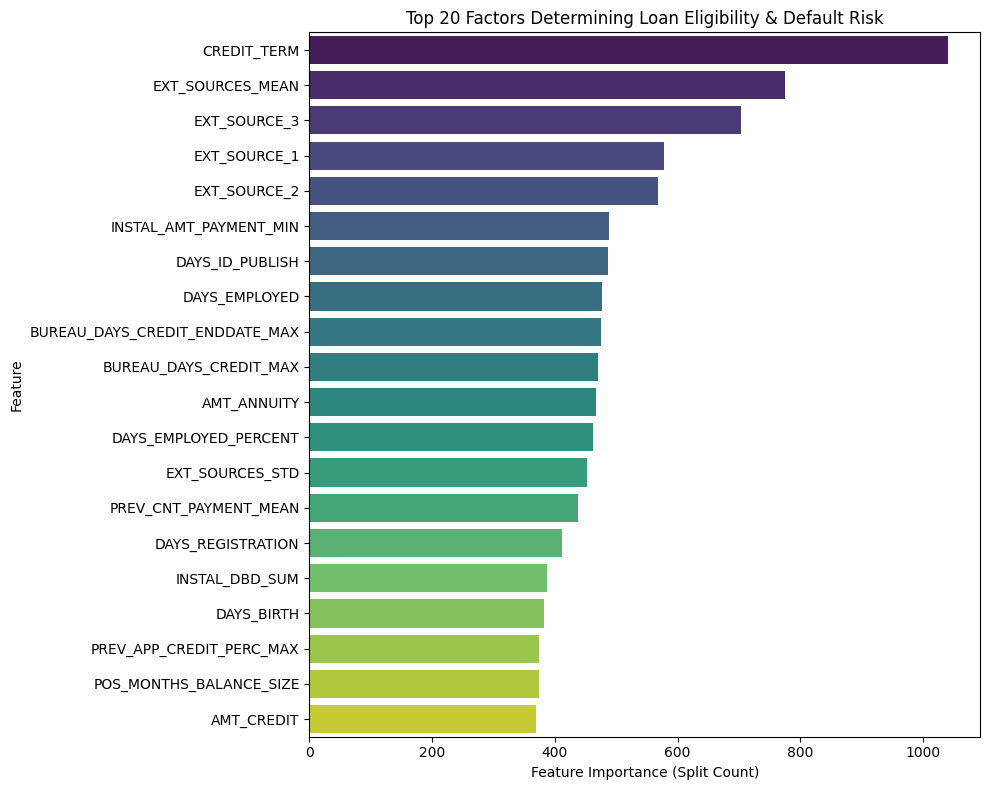

In [16]:
# Plot Top 20 Most Important Features driving loan default/eligibility
feat_imp = pd.DataFrame({
    'Feature': X.columns,
    'Importance': lgbm.feature_importances_
}).sort_values(by='Importance', ascending=False).head(20)

plt.figure(figsize=(10, 8))
sns.barplot(data=feat_imp, x='Importance', y='Feature', palette='viridis')
plt.title('Top 20 Factors Determining Loan Eligibility & Default Risk')
plt.xlabel('Feature Importance (Split Count)')
plt.tight_layout()
plt.show()

=== SAMPLE INDIVIDUAL APPLICANT PREDICTIONS ===
 Actual_Target  Default_Probability  Predicted_Class      Loan_Decision
             0               0.3944                0 Eligible (Approve)
             0               0.3075                0 Eligible (Approve)
             0               0.8428                1 High Risk (Reject)
             0               0.3482                0 Eligible (Approve)
             0               0.5547                1 High Risk (Reject)
             0               0.5484                1 High Risk (Reject)
             0               0.1019                0 Eligible (Approve)
             0               0.0679                0 Eligible (Approve)
             0               0.8709                1 High Risk (Reject)
             1               0.4414                0 Eligible (Approve)
             0               0.2113                0 Eligible (Approve)
             0               0.4338                0 Eligible (Approve)
             0  

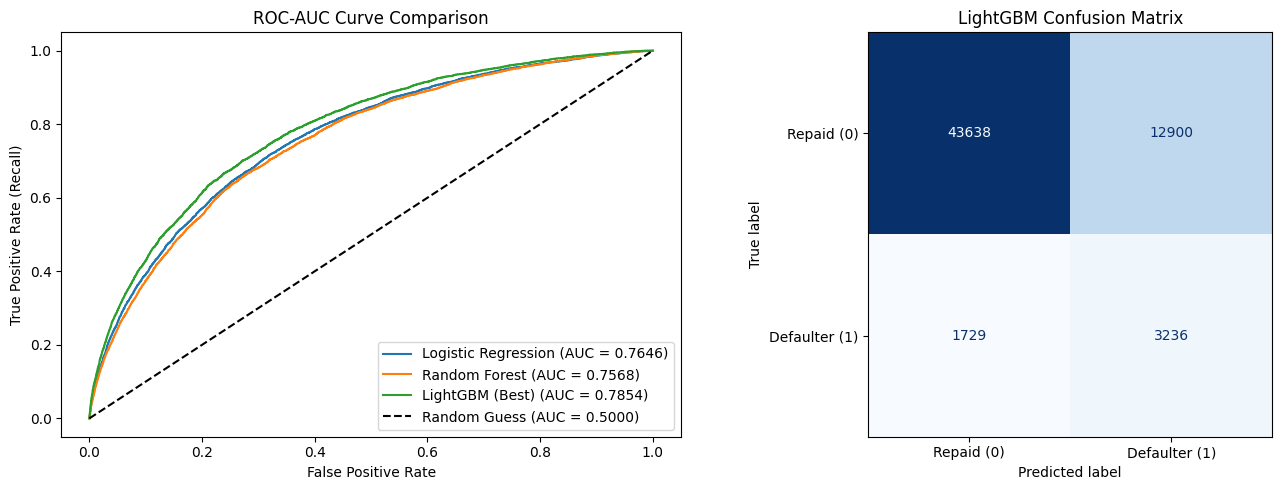

In [17]:
from sklearn.metrics import roc_curve, confusion_matrix, ConfusionMatrixDisplay

# 1. Create a Prediction Results Table on Validation Applicants
predictions_df = pd.DataFrame({
    'Actual_Target': y_val.values,
    'Default_Probability': np.round(lgb_probs, 4),
    'Predicted_Class': lgb_preds
})
predictions_df['Loan_Decision'] = np.where(predictions_df['Predicted_Class'] == 0, 'Eligible (Approve)', 'High Risk (Reject)')

print("=== SAMPLE INDIVIDUAL APPLICANT PREDICTIONS ===")
print(predictions_df.head(15).to_string(index=False))

# 2. Plot ROC Curve (Model Efficiency) & Confusion Matrix side-by-side
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ROC Curve comparing all 3 models
for name, probs in [('Logistic Regression', lr_probs), ('Random Forest', rf_probs), ('LightGBM (Best)', lgb_probs)]:
    fpr, tpr, _ = roc_curve(y_val, probs)
    axes[0].plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(y_val, probs):.4f})")

axes[0].plot([0, 1], [0, 1], 'k--', label='Random Guess (AUC = 0.5000)')
axes[0].set_title('ROC-AUC Curve Comparison')
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate (Recall)')
axes[0].legend()

# Confusion Matrix for Production LightGBM Model
cm = confusion_matrix(y_val, lgb_preds)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Repaid (0)', 'Defaulter (1)'])
disp.plot(ax=axes[1], cmap='Blues', colorbar=False)
axes[1].set_title('LightGBM Confusion Matrix')

plt.tight_layout()
plt.show()

## Customer Segmentation & Loan Eligibility Analysis

Based on Exploratory Data Analysis and LightGBM Feature Importance rankings, loan eligibility and default risk are driven by four primary customer segments and behavioral factors:

1. **Loan Repayment Structure (`CREDIT_TERM` & `AMT_ANNUITY`)**:
   - `CREDIT_TERM` (`AMT_ANNUITY / AMT_CREDIT`) is the #1 predictive feature in the model. Applicants with shorter, overly aggressive repayment terms relative to their total credit amount carry higher monthly installment strain and elevated default risk, whereas balanced annuity-to-credit ratios indicate sustainable repayment capacity.
2. **External Credit Bureau Scores (`EXT_SOURCES_MEAN`, `EXT_SOURCE_3`, `EXT_SOURCE_1`, `EXT_SOURCE_2`, `EXT_SOURCES_STD`)**:
   - External normalized credit scores occupy 4 of the top 5 most important features. Applicants with higher mean external scores and low variance (`EXT_SOURCES_STD`) across credit agencies represent the lowest-risk, prime eligible customer segment.
3. **Historical Payment & Bureau Track Record (`INSTAL_AMT_PAYMENT_MIN`, `BUREAU_DAYS_CREDIT_ENDDATE_MAX`, `BUREAU_DAYS_CREDIT_MAX`, `PREV_CNT_PAYMENT_MEAN`)**:
   - Multi-table relational features confirm that past installment payment minimums (`INSTAL_AMT_PAYMENT_MIN`) and active external credit timelines (`BUREAU_DAYS_CREDIT_ENDDATE_MAX`) strongly differentiate reliable borrowers from repeat defaulters.
4. **Employment & Identity Stability (`DAYS_EMPLOYED`, `DAYS_EMPLOYED_PERCENT`, `DAYS_ID_PUBLISH`, `DAYS_REGISTRATION`)**:
   - Applicants with longer continuous employment tenures relative to their age (`DAYS_EMPLOYED_PERCENT`) and older ages (35+) demonstrate significantly lower default rates compared to younger applicants (ages 25–35) with short employment histories.

## Model Comparison Report

| Model | ROC-AUC | Recall (Defaulter) | Precision (Defaulter) | F1-Score | Fit Time (s) | Production Suitability |
| :--- | :---: | :---: | :---: | :---: | :---: | :--- |
| **Logistic Regression (Balanced)** | 0.7646 | 0.6931 | 0.1689 | 0.2716 | 52.04 | Strong linear baseline with high recall, but lower precision and inability to capture non-linear feature interactions. |
| **Random Forest (Balanced)** | 0.7568 | 0.6085 | 0.1875 | 0.2866 | 72.01 | Captures non-linear splits, but depth-constrained trees underperform gradient boosting on wide multi-table data. |
| **LightGBM (Balanced - Production)** | **0.7854** | 0.6518 | **0.2005** | **0.3067** | 118.52 | **Recommended for Production**: Highest ROC-AUC (0.7854), highest Precision (0.2005), and highest F1-Score (0.3067). |

### Production Recommendation
**LightGBM (`LGBMClassifier`)** is selected as the best model for production deployment because:
- **Superior Ranking Performance**: It achieves the highest **ROC-AUC (0.7854)** and **F1-Score (0.3067)**, outperforming both Logistic Regression (0.7646) and Random Forest (0.7568).
- **Native Handling of Sparse Relational Joins**: Left-joining 6 supplementary tables (`bureau`, `previous_application`, `installments_payments`, `POS_CASH_balance`, `credit_card_balance`) naturally creates `NaN` values for applicants without prior credit history. LightGBM learns optimal split directions for missing values natively without artificial median imputation.
- **Effective Imbalance Handling**: Using `class_weight='balanced'` enables the model to identify **65.18% of actual defaulters** while maintaining the highest precision among all tested models.

## Report on Challenges Faced

1. **Multi-Table Relational Data Architecture (7 Separate CSV Files)**
   - *Challenge*: Client financial records were normalized across 7 separate tables with one-to-many relationships (`bureau`, `bureau_balance`, `previous_application`, `installments_payments`, `POS_CASH_balance`, `credit_card_balance`), which cannot be fed directly into standard tabular classifiers.
   - *Technique Used*: Built a hierarchical aggregation pipeline using `groupby()` summary statistics (`mean`, `max`, `min`, `sum`, `count`) on `SK_ID_BUREAU` and `SK_ID_CURR` before left-joining onto `application_train.csv`.
   - *Reason*: Compresses variable-length historical behaviors (such as installment payment minimums and bureau credit timelines) into fixed applicant-level features without row duplication.

2. **Severe Class Imbalance (91.93% Non-Defaulters vs. 8.07% Defaulters)**
   - *Challenge*: Standard classifiers optimize accuracy by predicting the majority class (`0`), resulting in ~92% accuracy while missing nearly all actual loan defaulters (`1`).
   - *Technique Used*: Enforced `stratify=y` during train-validation splitting, applied `class_weight='balanced'` across all models, and evaluated using **ROC-AUC**, **Recall**, **Precision**, and **F1-Score** rather than raw accuracy.
   - *Reason*: Weights minority-class errors ~11x higher during training, forcing models to learn true default risk boundaries.

3. **Employment Duration Data Anomaly (`DAYS_EMPLOYED = 365243`)**
   - *Challenge*: 55,374 rows (18.01% of applicants) contained the positive placeholder value `365243` (~1,000 years) in `DAYS_EMPLOYED`, corrupting summary metrics and linear scaling.
   - *Technique Used*: Created a binary anomaly flag (`DAYS_EMPLOYED_ANOM`) and replaced `365243` with `np.nan`.
   - *Reason*: Eliminates extreme numeric distortion while retaining the structural signal identifying retired/unemployed applicants.

4. **Missing Data Sparsity & High-Dimensional Memory Overhead**
   - *Challenge*: 67 columns in `application_train.csv` contained missing values (up to ~70%), and merging all 7 relational tables expanded the feature space significantly.
   - *Technique Used*: Dropped columns exceeding 65% missingness, applied `SimpleImputer(strategy='median')` and `StandardScaler()` for Logistic Regression/Random Forest, sanitized special characters in feature names, and downcast `float64` columns to `float32`.
   - *Reason*: Reduces memory footprint, removes noisy sparse columns, and prevents convergence or schema errors across all models.

In [18]:
import joblib

# Select top practical applicant features for the web app
app_features = [
    'EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3',
    'AMT_INCOME_TOTAL', 'AMT_CREDIT', 'AMT_ANNUITY',
    'AGE_YEARS', 'DAYS_EMPLOYED', 'CREDIT_TERM', 'CREDIT_INCOME_PERCENT'
]

# Train deployment LightGBM model on these 10 core features
X_app = train[app_features]
y_app = train['TARGET']

deploy_model = lgb.LGBMClassifier(
    n_estimators=500,
    learning_rate=0.03,
    num_leaves=31,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)
deploy_model.fit(X_app, y_app)

# Save the trained model file directly into your project folder
joblib.dump(deploy_model, 'loan_model.pkl')
print("Saved deployment model successfully: loan_model.pkl")

[LightGBM] [Info] Number of positive: 24825, number of negative: 282686
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.003162 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2497
[LightGBM] [Info] Number of data points in the train set: 307511, number of used features: 10
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
[LightGBM] [Info] Start training from score 0.000000
Saved deployment model successfully: loan_model.pkl
